# Data science salaries: model comparison, redone in Python

Redo of the PSTAT 131 R project (`main.Rmd`). The R analysis had an evaluation bug (the linear model's test MSE mixed log and USD scales), unscaled KNN, a single train/test split and duplicate rows leaking across the split. Here every model is scored in USD on held-out folds. Run `model_comparison.py` and `tune_models.py` first to regenerate `outputs/`.

In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from model_comparison import load, CAT

pd.options.display.float_format = '{:,.3f}'.format
raw, dedup = load(False), load(True)
print(f'{len(raw)} rows, {len(raw)-len(dedup)} exact duplicates ({1-len(dedup)/len(raw):.0%}) -> {len(dedup)} unique')

3755 rows, 1172 exact duplicates (31%) -> 2583 unique


## 1. The target and the data

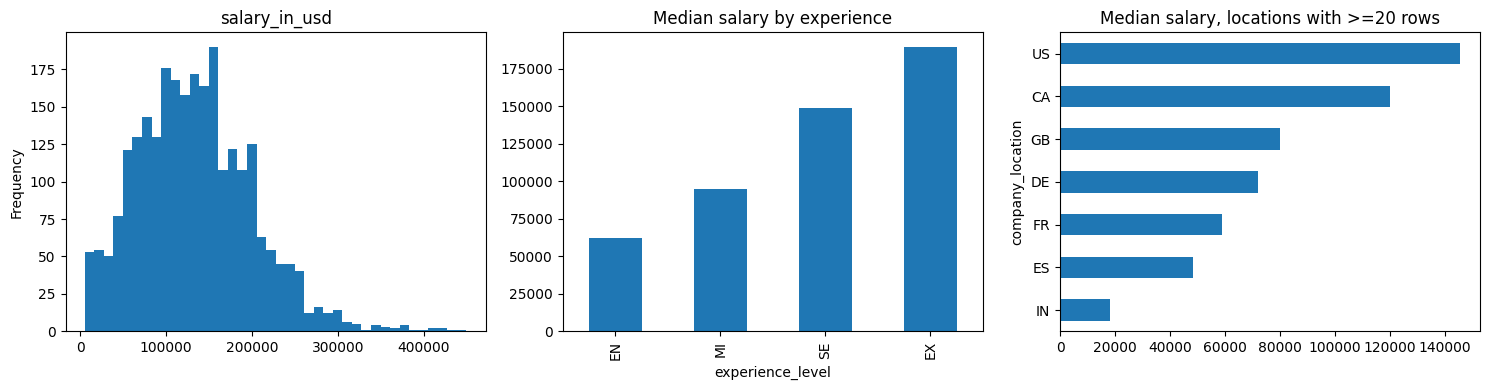

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
dedup.salary_in_usd.plot.hist(bins=40, ax=ax[0], title='salary_in_usd'); 
dedup.groupby('experience_level').salary_in_usd.median().reindex(['EN','MI','SE','EX']).plot.bar(ax=ax[1], title='Median salary by experience')
dedup.groupby('company_location').salary_in_usd.agg(['median','count']).query('count>=20')['median'].sort_values().plot.barh(ax=ax[2], title='Median salary, locations with >=20 rows')
plt.tight_layout()

Most rows are US companies, so location effects are dominated by the US versus the rest. Many job titles and locations have only a handful of rows, which limits what any model can learn.

## 2. Duplicates inflate every score

In [3]:
res = pd.read_csv('outputs/cv_results.csv')
piv = res.pivot(index='model', columns='data', values='rmse')
piv['inflation'] = piv['deduplicated'] - piv['with dupes']
piv.sort_values('deduplicated').round(0)

data,deduplicated,with dupes,inflation
model,,,
Ridge (log target),"51,175.000","48,888.000","2,287.000"
Random forest,"51,577.000","48,248.000","3,329.000"
XGBoost (log target),"51,632.000","48,908.000","2,724.000"
LightGBM (log target),"52,254.000","49,264.000","2,990.000"
KNN k=15 (scaled),"55,639.000","51,949.000","3,690.000"
Median baseline,"67,224.000","63,083.000","4,141.000"


Every model looks roughly $2,300 to $4,100 better when duplicates stay in, because copies of the same row land in both train and test folds. All comparisons below use the deduplicated data.

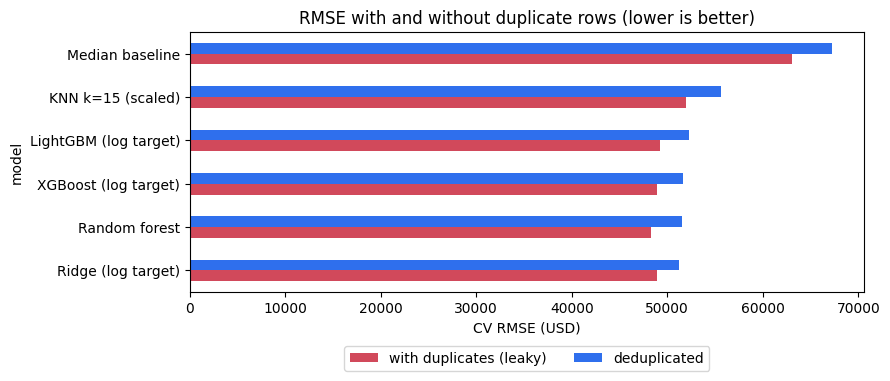

In [4]:
piv2 = piv.sort_values('deduplicated')
ax = piv2[['with dupes', 'deduplicated']].plot.barh(figsize=(9, 4), color=['#d1495b', '#2f6fed'], title='RMSE with and without duplicate rows (lower is better)')
ax.set_xlabel('CV RMSE (USD)'); ax.legend(['with duplicates (leaky)', 'deduplicated'], loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2); plt.tight_layout()

## 3. Model comparison (repeated 5-fold CV, 3 repeats, deduplicated)

,rmse,rmse_sd,mae,r2
model,,,,
Ridge (log target),"51,174.677","3,172.263","36,666.110",0.416
Random forest,"51,577.205","2,942.262","38,004.502",0.407
XGBoost (log target),"51,632.356","3,102.313","36,957.257",0.405
LightGBM (log target),"52,253.835","3,193.825","37,599.219",0.391
KNN k=15 (scaled),"55,639.393","3,179.596","41,953.520",0.310
Median baseline,"67,224.093","2,904.889","52,868.005",-0.007


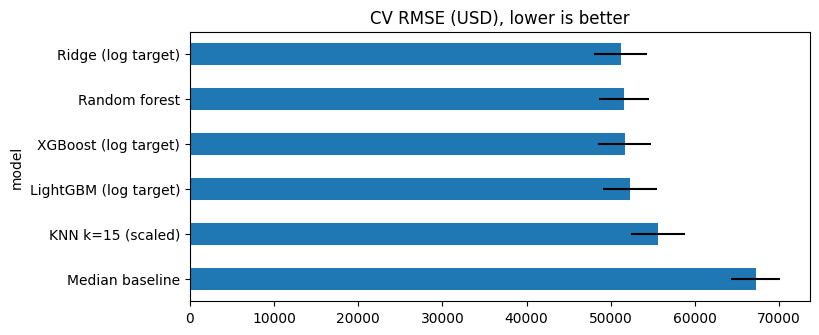

In [5]:
d = res[res.data=='deduplicated'].set_index('model').sort_values('rmse')
display(d[['rmse','rmse_sd','mae','r2']].round(3))
d['rmse'].plot.barh(xerr=d['rmse_sd'], figsize=(8,3.5), title='CV RMSE (USD), lower is better'); plt.gca().invert_yaxis()

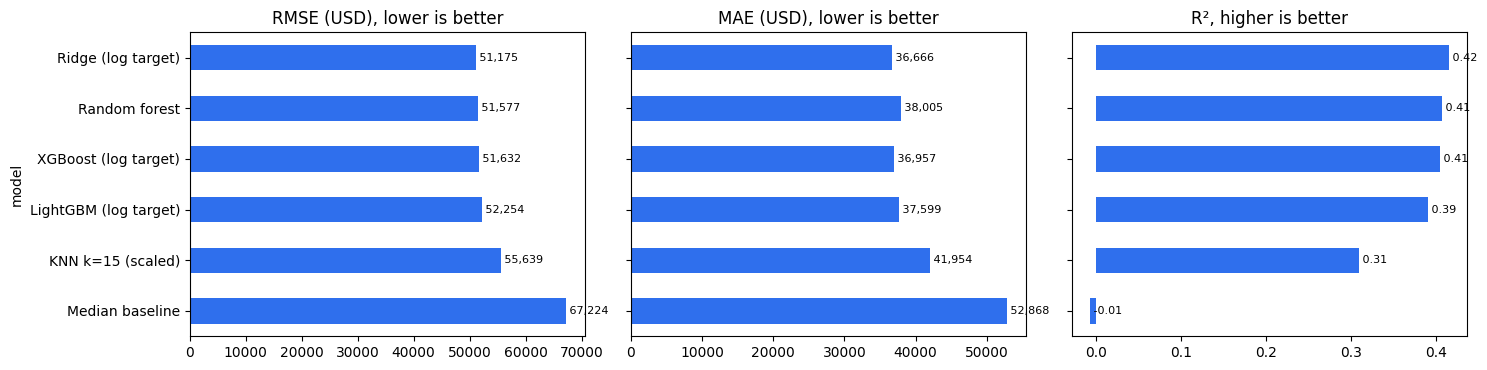

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
order = d.index.tolist()
for a, (col, title) in zip(ax, [('rmse', 'RMSE (USD), lower is better'), ('mae', 'MAE (USD), lower is better'), ('r2', 'R², higher is better')]):
    d[col].loc[order].plot.barh(ax=a, title=title, color='#2f6fed'); a.invert_yaxis()
    for i, v in enumerate(d[col].loc[order]): a.text(v, i, f' {v:,.0f}' if col != 'r2' else f' {v:.2f}', va='center', fontsize=8)
plt.tight_layout()

### Predicted vs actual (out-of-fold)
Every model hugs the diagonal loosely and underpredicts the highest salaries, which is the signature of a feature set that cannot see what makes a salary extreme.

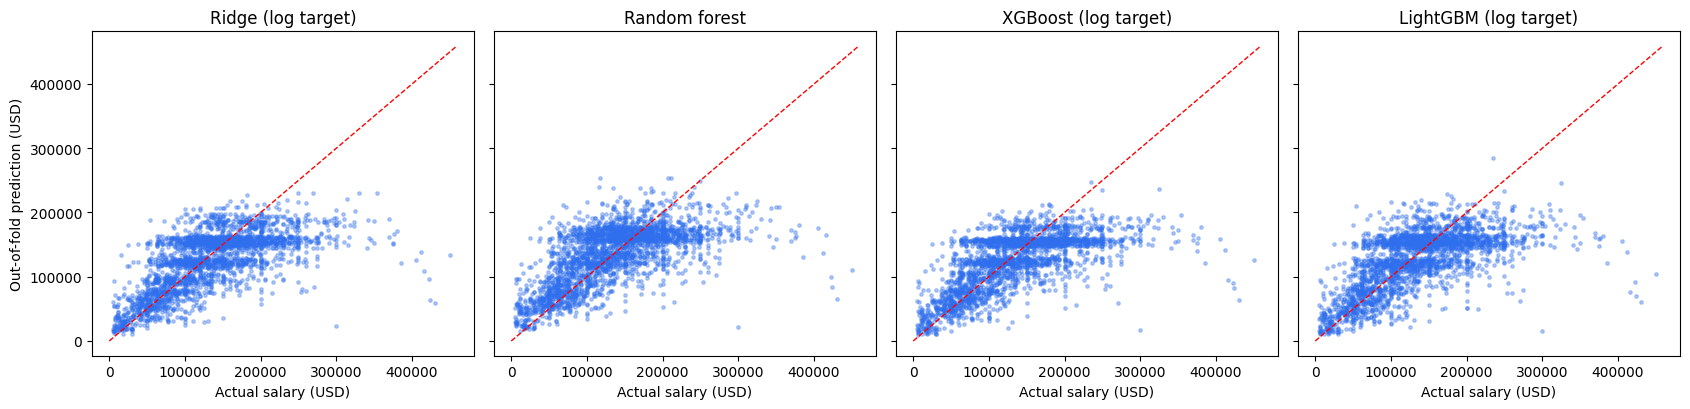

In [7]:
import numpy as np
from sklearn.model_selection import KFold, cross_val_predict
from model_comparison import models, CAT, NUM, TARGET

X, y = dedup[CAT + NUM], dedup[TARGET]
shown = ['Ridge (log target)', 'Random forest', 'XGBoost (log target)', 'LightGBM (log target)']
ms = models()
oof = {m: cross_val_predict(ms[m], X, y, cv=KFold(5, shuffle=True, random_state=123)) for m in shown}

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharex=True, sharey=True)
lim = [0, y.max() * 1.02]
for a, m in zip(axes, shown):
    a.scatter(y, oof[m], s=6, alpha=.35, color='#2f6fed'); a.plot(lim, lim, 'r--', lw=1)
    a.set_title(m); a.set_xlabel('Actual salary (USD)')
axes[0].set_ylabel('Out-of-fold prediction (USD)'); plt.tight_layout()

### Residuals

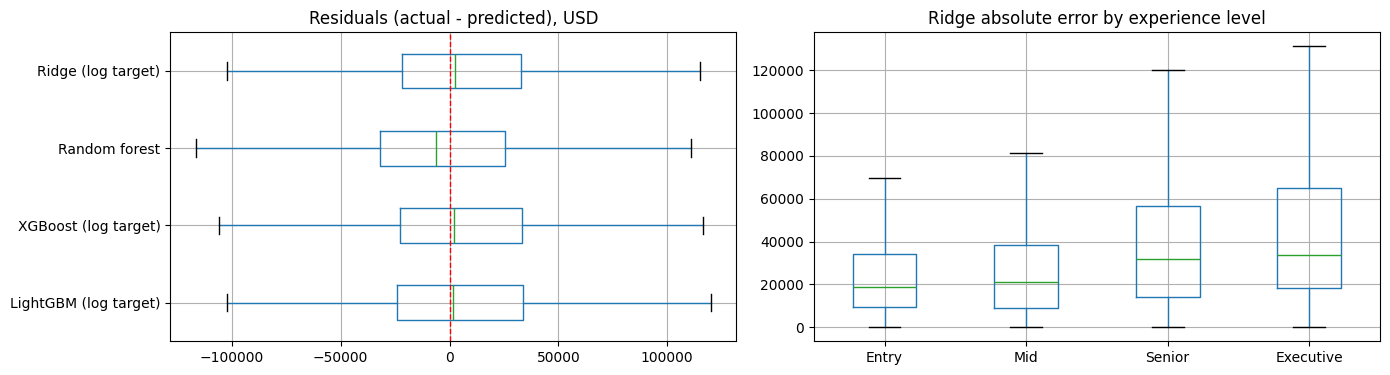

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
res = pd.DataFrame({m: y - oof[m] for m in shown})
res.boxplot(ax=ax[0], vert=False, showfliers=False); ax[0].axvline(0, color='r', ls='--', lw=1)
ax[0].set_title('Residuals (actual - predicted), USD'); ax[0].invert_yaxis()
lvl = pd.Categorical(dedup.experience_level.map({'EN': 'Entry', 'MI': 'Mid', 'SE': 'Senior', 'EX': 'Executive'}), categories=['Entry', 'Mid', 'Senior', 'Executive'], ordered=True)
tmp = pd.DataFrame({'level': lvl, 'abs error': (y - oof['Ridge (log target)']).abs()})
tmp.boxplot(by='level', column='abs error', ax=ax[1], showfliers=False)
ax[1].set_title('Ridge absolute error by experience level'); ax[1].set_xlabel(''); plt.suptitle('')
plt.tight_layout()

Ridge on a log target is as good as anything else. The R report's claim that tree methods beat linear regression "by two digits" came from comparing log-scale predictions with dollars. With the scale fixed, they are within about 1% of each other, and scaled KNN is a reasonable baseline rather than a failure.

## 4. Does tuning help? (nested CV)

In [9]:
tuned = pd.read_csv('outputs/tuned_results.csv').set_index('model')
base = d.loc[['Random forest','XGBoost (log target)','LightGBM (log target)'], ['rmse','r2']]
base.index = [i + ' tuned' for i in base.index]
cmp = base.join(tuned[['rmse','r2']], lsuffix=' default', rsuffix=' tuned')
cmp.columns = ['rmse default','r2 default','rmse tuned','r2 tuned']
cmp.round(3)

,rmse default,r2 default,rmse tuned,r2 tuned
Random forest tuned,"51,577.205",0.407,"51,535.667",0.409
XGBoost (log target) tuned,"51,632.356",0.405,"51,994.579",0.398
LightGBM (log target) tuned,"52,253.835",0.391,"52,053.619",0.396


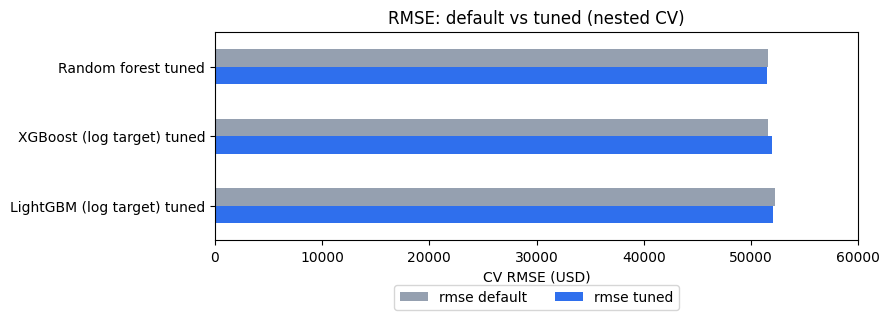

In [10]:
ax = cmp[['rmse default', 'rmse tuned']].plot.barh(figsize=(9, 3.4), color=['#95a0b0', '#2f6fed'], title='RMSE: default vs tuned (nested CV)')
ax.set_xlabel('CV RMSE (USD)'); ax.set_xlim(0, 60000); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2); ax.invert_yaxis(); plt.tight_layout()

Tuning with randomized search inside each outer fold changes RMSE by well under 1%, which is inside the fold-to-fold noise. The limit is the information in seven features, not the hyperparameters.

## 5. What drives salary

(np.float64(-0.5), np.float64(1199.5), np.float64(1124.5), np.float64(-0.5))

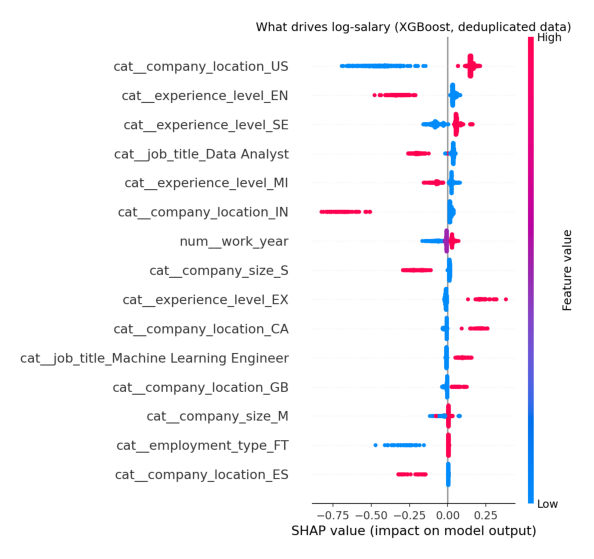

In [11]:
plt.figure(figsize=(8,7)); plt.imshow(mpimg.imread('outputs/shap_summary.png')); plt.axis('off')

A US company location is the largest single effect on log-salary. Experience level comes next: entry level pulls salary down and senior and executive levels push it up. An Indian company location and a Data Analyst title lower it, and Machine Learning Engineer and later work years raise it. These are associations in a survey sample, not causal effects.

## 6. Prediction intervals

In [12]:
cov = json.load(open('outputs/interval_coverage.json'))
print(f"Nominal {cov['nominal']:.0%} interval: out-of-fold coverage {cov['coverage']:.1%}, median width ${cov['median_width']:,.0f}")

Nominal 80% interval: out-of-fold coverage 77.5%, median width $115,245


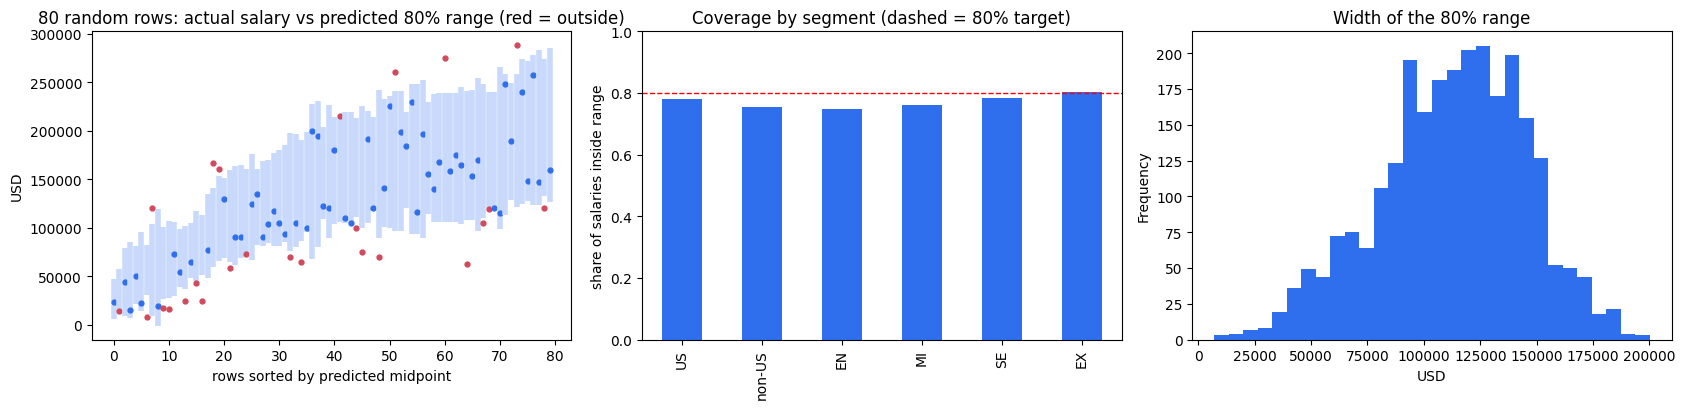

In [13]:
import numpy as np
from tune_models import oof_intervals
lo, hi = oof_intervals(dedup)
yv = dedup.salary_in_usd.to_numpy()
inside = (yv >= lo) & (yv <= hi)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
idx = np.random.default_rng(1).choice(len(yv), 80, replace=False); idx = idx[np.argsort(((lo + hi) / 2)[idx])]
for j, i in enumerate(idx):
    ax[0].vlines(j, lo[i], hi[i], color='#c9d9fb', lw=4)
    ax[0].plot(j, yv[i], '.', color='#2f6fed' if inside[i] else '#d1495b', ms=7)
ax[0].set_title('80 random rows: actual salary vs predicted 80% range (red = outside)'); ax[0].set_xlabel('rows sorted by predicted midpoint'); ax[0].set_ylabel('USD')

seg = pd.DataFrame({'inside': inside, 'US': np.where(dedup.company_location == 'US', 'US', 'non-US'),
                    'level': dedup.experience_level})
cov = pd.concat([seg.groupby('US').inside.mean(), seg.groupby('level').inside.mean().reindex(['EN', 'MI', 'SE', 'EX'])])
cov.plot.bar(ax=ax[1], color='#2f6fed'); ax[1].axhline(.8, color='r', ls='--', lw=1); ax[1].set_ylim(0, 1)
ax[1].set_title('Coverage by segment (dashed = 80% target)'); ax[1].set_ylabel('share of salaries inside range')

width = pd.Series(hi - lo, index=dedup.index); width.plot.hist(bins=30, ax=ax[2], color='#2f6fed')
ax[2].set_title('Width of the 80% range'); ax[2].set_xlabel('USD')
plt.tight_layout()

LightGBM quantile models give an 80% interval that covers about 77% of held-out salaries, close to nominal, but the median interval is over $100k wide. That is the honest picture for a point estimate with R² around 0.4, and it is why the planned web app should show a range, not a single number.

## Next steps
- Build the estimator and explorer UI on a quantile model (the interval is the product).
- Collect or join more informative features (company industry, skills, years of experience) since tuning can't fix missing signal.
- Check calibration of the interval per segment (US vs non-US, entry vs senior).